In [30]:
import pandas as pd
import matplotlib.dates as mdates
import numpy as np
import os
import matplotlib.pyplot as plt
os.makedirs("plots", exist_ok=True)
df = pd.read_csv("data.csv")
print(f"Shape: {df.shape}")


Shape: (34160, 53)


<positron-console-cell-30>:7: DtypeWarning: Columns (26,27,38,39,50,51) have mixed types. Specify dtype option on import or set low_memory=False.


In [16]:
print(f"\nColumns:\n{list(df.columns)}")


Columns:
['main_ident', 'timeslot_datetime_from', 'channel_id', 'share_15_54', 'share_15_54_3mo_mean', 'ch9__f_1', 'ch9__f_3', 'ch9__f_2', 'ch9__f_4', 'ch9__f_6', 'ch9__f_5', 'ch9__f_7', 'ch9__f_8', 'ch9__f_9', 'ch9__f_10', 'ch9__f_11', 'ch9__f_12', 'ch3__f_1', 'ch3__f_3', 'ch3__f_2', 'ch3__f_4', 'ch3__f_6', 'ch3__f_5', 'ch3__f_7', 'ch3__f_8', 'ch3__f_9', 'ch3__f_10', 'ch3__f_11', 'ch3__f_12', 'ch54__f_1', 'ch54__f_3', 'ch54__f_2', 'ch54__f_4', 'ch54__f_6', 'ch54__f_5', 'ch54__f_7', 'ch54__f_8', 'ch54__f_9', 'ch54__f_10', 'ch54__f_11', 'ch54__f_12', 'ch4__f_1', 'ch4__f_3', 'ch4__f_2', 'ch4__f_4', 'ch4__f_6', 'ch4__f_5', 'ch4__f_7', 'ch4__f_8', 'ch4__f_9', 'ch4__f_10', 'ch4__f_11', 'ch4__f_12']


In [17]:
print(f"\nDtypes:\n{df.dtypes}")


Dtypes:
main_ident                  int64
timeslot_datetime_from     object
channel_id                  int64
share_15_54               float64
share_15_54_3mo_mean      float64
ch9__f_1                  float64
ch9__f_3                  float64
ch9__f_2                  float64
ch9__f_4                  float64
ch9__f_6                  float64
ch9__f_5                  float64
ch9__f_7                  float64
ch9__f_8                  float64
ch9__f_9                  float64
ch9__f_10                 float64
ch9__f_11                 float64
ch9__f_12                 float64
ch3__f_1                  float64
ch3__f_3                  float64
ch3__f_2                  float64
ch3__f_4                  float64
ch3__f_6                  float64
ch3__f_5                  float64
ch3__f_7                  float64
ch3__f_8                  float64
ch3__f_9                  float64
ch3__f_10                  object
ch3__f_11                  object
ch3__f_12                 float64
ch54_

In [18]:
print(f"\nChannel IDs: {df['channel_id'].unique()}")


Channel IDs: [ 3  4  9 54]


In [19]:
print(f"\nDate range: {df['timeslot_datetime_from'].min()} → {df['timeslot_datetime_from'].max()}")


Date range: 2022-01-01T17:10:00.000000 → 2024-01-13T23:45:00.000000


In [20]:
print(f"\nTarget stats:\n{df['share_15_54'].describe()}")


Target stats:
count    34160.000000
mean        10.361465
std          8.704869
min          0.000000
25%          3.551612
50%          7.173055
75%         15.437194
max         56.075580
Name: share_15_54, dtype: float64


In [21]:
print(f"\nNull counts:\n{df.isnull().sum()[df.isnull().sum() > 0]}")


Null counts:
ch9__f_3       2562
ch9__f_2       2562
ch9__f_4       2552
ch9__f_6       2533
ch9__f_5       2533
ch9__f_7      34160
ch9__f_8      34160
ch9__f_9      34160
ch9__f_10     34160
ch9__f_11     34160
ch9__f_12      3394
ch3__f_1        172
ch3__f_3       4240
ch3__f_2       4240
ch3__f_4       4240
ch3__f_6       5139
ch3__f_5       5139
ch3__f_7       8217
ch3__f_8       7779
ch3__f_9       7779
ch3__f_10      7779
ch3__f_11      7779
ch3__f_12     13753
ch54__f_1       285
ch54__f_3       885
ch54__f_2       885
ch54__f_4       878
ch54__f_6      1018
ch54__f_5      1018
ch54__f_7      5971
ch54__f_8      5840
ch54__f_9      5840
ch54__f_10     5840
ch54__f_11     5840
ch54__f_12     5099
ch4__f_1        353
ch4__f_3       6791
ch4__f_2       6791
ch4__f_4       6791
ch4__f_6       8386
ch4__f_5       8386
ch4__f_7       9441
ch4__f_8       9209
ch4__f_9       9209
ch4__f_10      9209
ch4__f_11      9209
ch4__f_12     15395
dtype: int64


In [22]:
print(f"\nSample rows:\n{df.head(3).to_string()}")


Sample rows:
          main_ident      timeslot_datetime_from  channel_id  share_15_54  share_15_54_3mo_mean  ch9__f_1  ch9__f_3  ch9__f_2  ch9__f_4   ch9__f_6  ch9__f_5  ch9__f_7  ch9__f_8  ch9__f_9  ch9__f_10  ch9__f_11  ch9__f_12  ch3__f_1   ch3__f_3  ch3__f_2  ch3__f_4  ch3__f_6  ch3__f_5  ch3__f_7  ch3__f_8  ch3__f_9   ch3__f_10 ch3__f_11  ch3__f_12  ch54__f_1  ch54__f_3  ch54__f_2  ch54__f_4  ch54__f_6  ch54__f_5  ch54__f_7  ch54__f_8  ch54__f_9 ch54__f_10 ch54__f_11  ch54__f_12  ch4__f_1   ch4__f_3  ch4__f_2   ch4__f_4   ch4__f_6  ch4__f_5  ch4__f_7  ch4__f_8  ch4__f_9 ch4__f_10 ch4__f_11  ch4__f_12
0  32201011704400020  2022-01-01T17:10:00.000000           3    23.645990             21.232685  0.335878  72.12605     119.0  62.07395  59.357143       7.0       NaN       NaN       NaN        NaN        NaN        3.0   0.06993  61.584908      53.0  66.17598    62.625       8.0      74.0   29248.0       0.0  Romantický       USA        3.0   0.564886   60.18182       33.0  53.8030

Each row is a timeslot and contains features for all 4 channels simultaneously. Share 15-54 is the percentage of all people aged 15–54 who are currently watching TV that are tuned to this specific channel at that timeslot. So a share of 23.6 means "of everyone in the 15-54 demographic with their TV on right now, 23.6% are watching us." It's a zero-sum competition between channels 

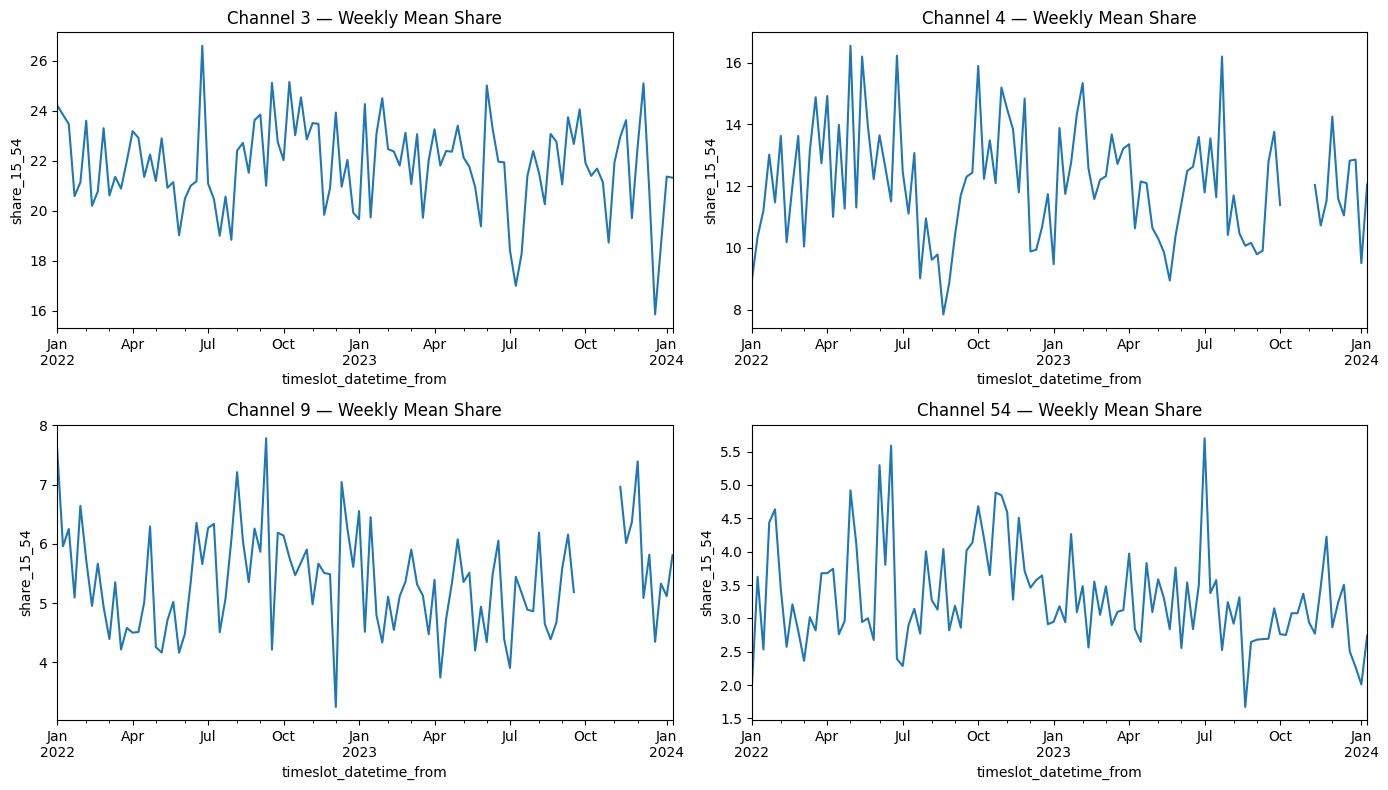

In [23]:
import matplotlib.pyplot as plt

df = pd.read_csv("data.csv", low_memory=False)
df['timeslot_datetime_from'] = pd.to_datetime(df['timeslot_datetime_from'])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, ch in zip(axes.flat, sorted(df['channel_id'].unique())):
    sub = df[df['channel_id'] == ch].set_index('timeslot_datetime_from')['share_15_54']
    sub.resample('W').mean().plot(ax=ax, title=f'Channel {ch} — Weekly Mean Share')
    ax.set_ylabel('share_15_54')
plt.tight_layout()
plt.savefig("channel_trends.png", dpi=120)
plt.show()

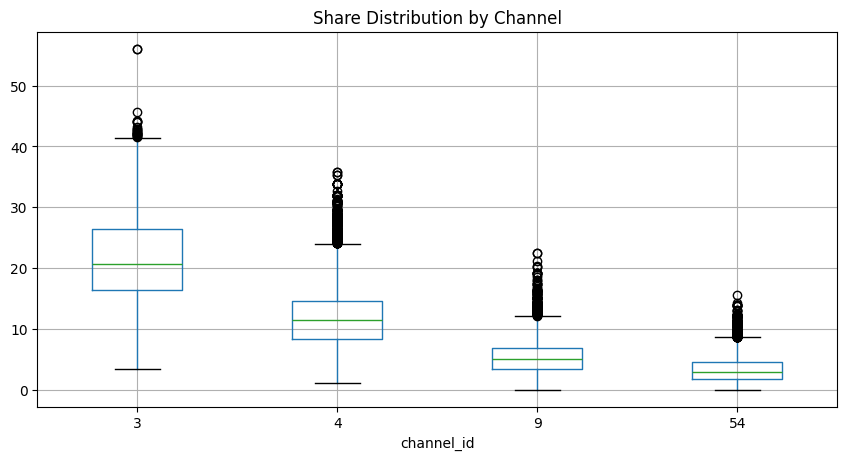

In [24]:
# Distribution per channel
fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(column='share_15_54', by='channel_id', ax=ax)
ax.set_title('Share Distribution by Channel')
plt.suptitle('')
plt.savefig("channel_distributions.png", dpi=120)
plt.show()

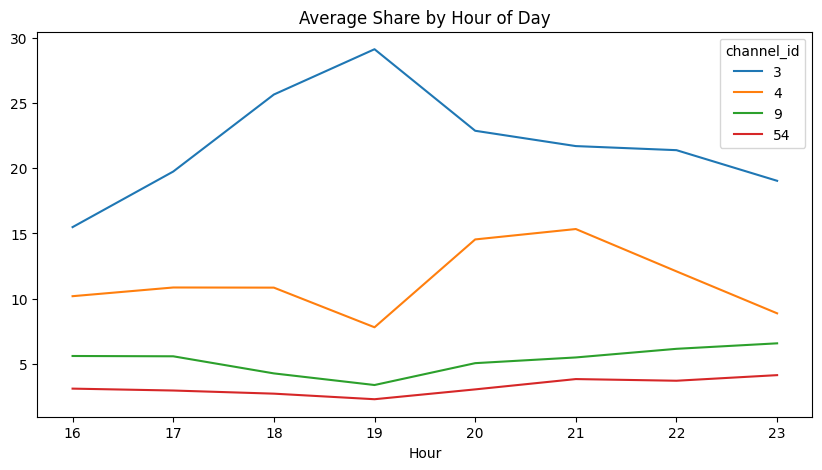

In [25]:
# Timeslot patterns (hour of day)
df['hour'] = df['timeslot_datetime_from'].dt.hour
fig, ax = plt.subplots(figsize=(10, 5))
df.groupby(['channel_id', 'hour'])['share_15_54'].mean().unstack(0).plot(ax=ax)
ax.set_title('Average Share by Hour of Day')
ax.set_xlabel('Hour')
plt.savefig("hourly_patterns.png", dpi=120)
plt.show()

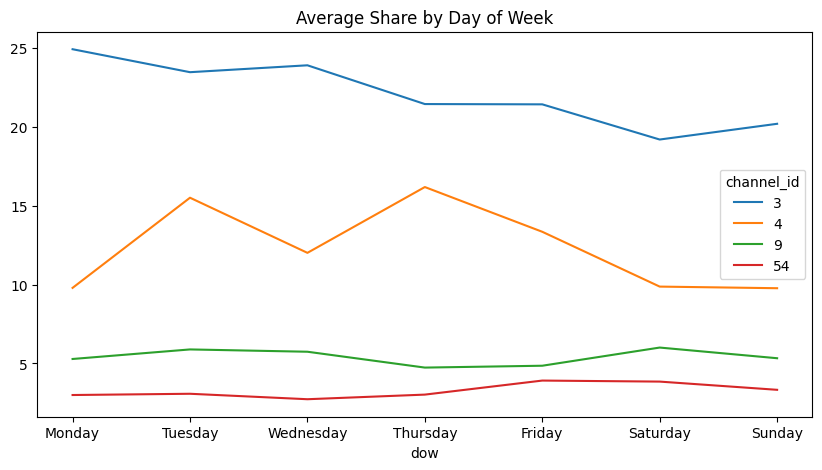

In [26]:
# Day of week
df['dow'] = df['timeslot_datetime_from'].dt.day_name()
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
fig, ax = plt.subplots(figsize=(10, 5))
df.groupby(['channel_id', 'dow'])['share_15_54'].mean().unstack(0).loc[dow_order].plot(ax=ax)
ax.set_title('Average Share by Day of Week')
plt.savefig("dow_patterns.png", dpi=120)
plt.show()

In [27]:
print(df.groupby('channel_id')['share_15_54'].agg(['mean','median','std','count']))

                 mean     median       std  count
channel_id                                       
3           21.713021  20.709547  7.173833   8545
4           12.119126  11.360578  5.567934   7392
9            5.392805   4.943759  2.804186   8753
54           3.339186   2.942778  2.148778   9470


In [28]:

df = pd.read_csv("data.csv", low_memory=False)
genre_cols = {'Channel 3': 'ch3__f_10', 'Channel 4': 'ch4__f_10',
              'Channel 9': 'ch9__f_10', 'Channel 54': 'ch54__f_10'}

for name, col in genre_cols.items():
    print(f"\n=== {name} ===")
    print(df[col].value_counts().head(10).to_string())


=== Channel 3 ===
Komedie          5227
Krimi            4231
Akční            3870
Reality-TV       2609
Drama            2286
Soutěžní         2256
Publicistický    1845
Fantasy          1032
Dobrodružný       926
Romantický        412

=== Channel 4 ===
Komedie          5038
Zábavný          2897
Reality-TV       2789
Krimi            2610
Dokumentární     2239
Rodinný          2178
Talk-show        1652
Drama            1470
Akční            1152
Publicistický    1004

=== Channel 9 ===
Series([], )

=== Channel 54 ===
Komedie        8205
Drama          5210
Akční          5162
Dobrodružný    1579
Krimi          1180
Thriller       1130
Romantický     1008
Sci-Fi          889
Western         806
Rodinný         700


Kanál 3 asi bude TV Nova, protože je nejpopulárnější. 54 bude Nova Cinema kvůli filmovým žánrům. na 4. kanálu je hodně komedie, mohla by to být Nova Fun. 9 bude sportovní kanál, protože nemá metadata o pořadu -> pravděpodobně vysílání sportu

# Task 1
Analyze the data and try to draw conclusions about the channels. We have selected four
channels (”channel id”) for you. The time column is labelled ”timeslot datetime from” and the
ID column of the movies is labelled ”main indent”.

In [33]:
# plot setup
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'font.size': 12,
    'axes.titlesize': 16,
    'axes.labelsize': 13,
    'legend.fontsize': 11,
    'figure.dpi': 150,
})
CHANNEL_NAMES = {
    3: 'Ch 3 (TV Nova)',
    4: 'Ch 4 (Fun)',
    9: 'Ch 9 (Sport)',
    54: 'Ch 54 (Cinema)',
}
CHANNEL_COLORS = {3: '#e63946', 4: '#457b9d', 9: '#2a9d8f', 54: '#e9c46a'}

In [ ]:
#přejmenování sloupců pro snadnější práci
df = pd.read_csv("data.csv", low_memory=False)
df['timeslot_datetime_from'] = pd.to_datetime(df['timeslot_datetime_from'])
df['hour'] = df['timeslot_datetime_from'].dt.hour
df['dow'] = df['timeslot_datetime_from'].dt.day_name()
df['month'] = df['timeslot_datetime_from'].dt.to_period('M')
df['date'] = df['timeslot_datetime_from'].dt.date
df['channel_name'] = df['channel_id'].map(CHANNEL_NAMES)
 
print(f"Loaded {len(df)} rows, {df['channel_id'].nunique()} channels")
print(f"Date range: {df['timeslot_datetime_from'].min()} → {df['timeslot_datetime_from'].max()}")

Loaded 34160 rows, 4 channels
Date range: 2022-01-01 17:10:00 → 2024-01-13 23:45:00


## Share Dynamics
Which channel dominates, which is niche? How volatile is each?

<positron-console-cell-37>:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


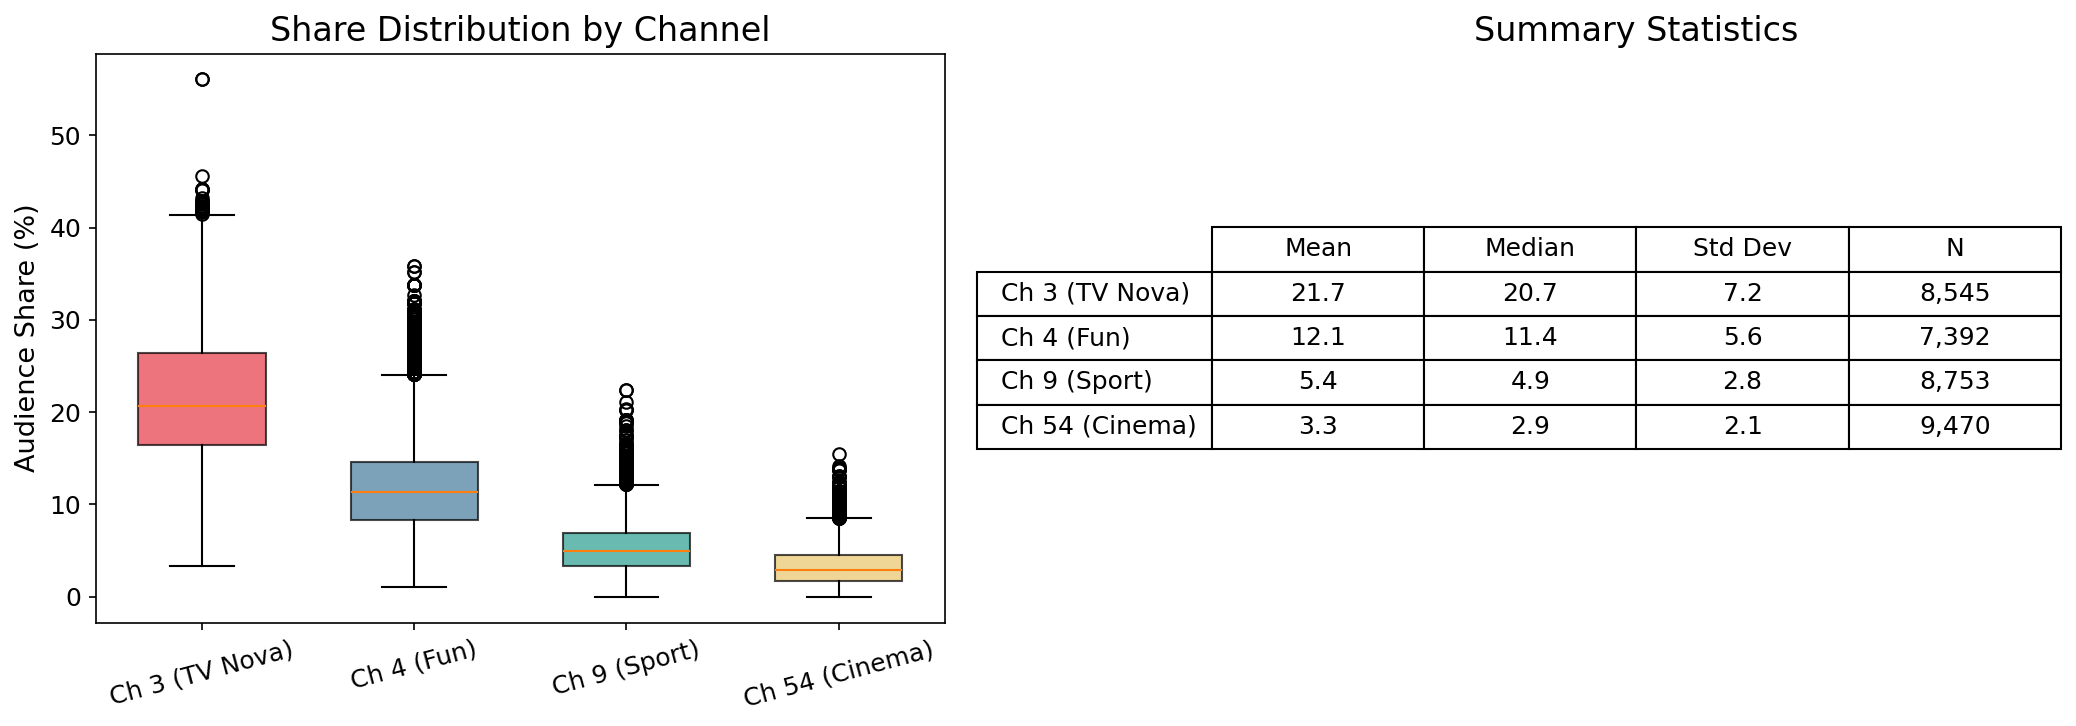

Saved: plots/01_share_dynamics.png


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Box plot
box_data = [df[df['channel_id'] == ch]['share_15_54'].dropna() for ch in sorted(CHANNEL_COLORS)]
box_labels = [CHANNEL_NAMES[ch] for ch in sorted(CHANNEL_COLORS)]
bp = axes[0].boxplot(box_data, labels=box_labels, patch_artist=True, widths=0.6)
for patch, ch in zip(bp['boxes'], sorted(CHANNEL_COLORS)):
    patch.set_facecolor(CHANNEL_COLORS[ch])
    patch.set_alpha(0.7)
axes[0].set_ylabel('Audience Share (%)')
axes[0].set_title('Share Distribution by Channel')
axes[0].tick_params(axis='x', rotation=15)
# Summary stats as a table
stats = df.groupby('channel_id')['share_15_54'].agg(['mean', 'median', 'std', 'count'])
stats.index = stats.index.map(CHANNEL_NAMES)
stats.columns = ['Mean', 'Median', 'Std Dev', 'N']
cell_text = [[f"{v:.1f}" if c != 'N' else f"{int(v):,}" for c, v in zip(stats.columns, row)] for row in stats.values]
table = axes[1].table(
    cellText=cell_text,
    rowLabels=stats.index,
    colLabels=stats.columns,
    cellLoc='center',
    loc='center',
)
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.8)
axes[1].axis('off')
axes[1].set_title('Summary Statistics')
 
plt.tight_layout()
plt.savefig("plots/01_share_dynamics.png", bbox_inches='tight')
plt.show()
print("Saved: plots/01_share_dynamics.png")

## Temporal patterns
Prime time effect per channel, weekday vs weekend differences, any seasonal trends.

### Týdenní trend

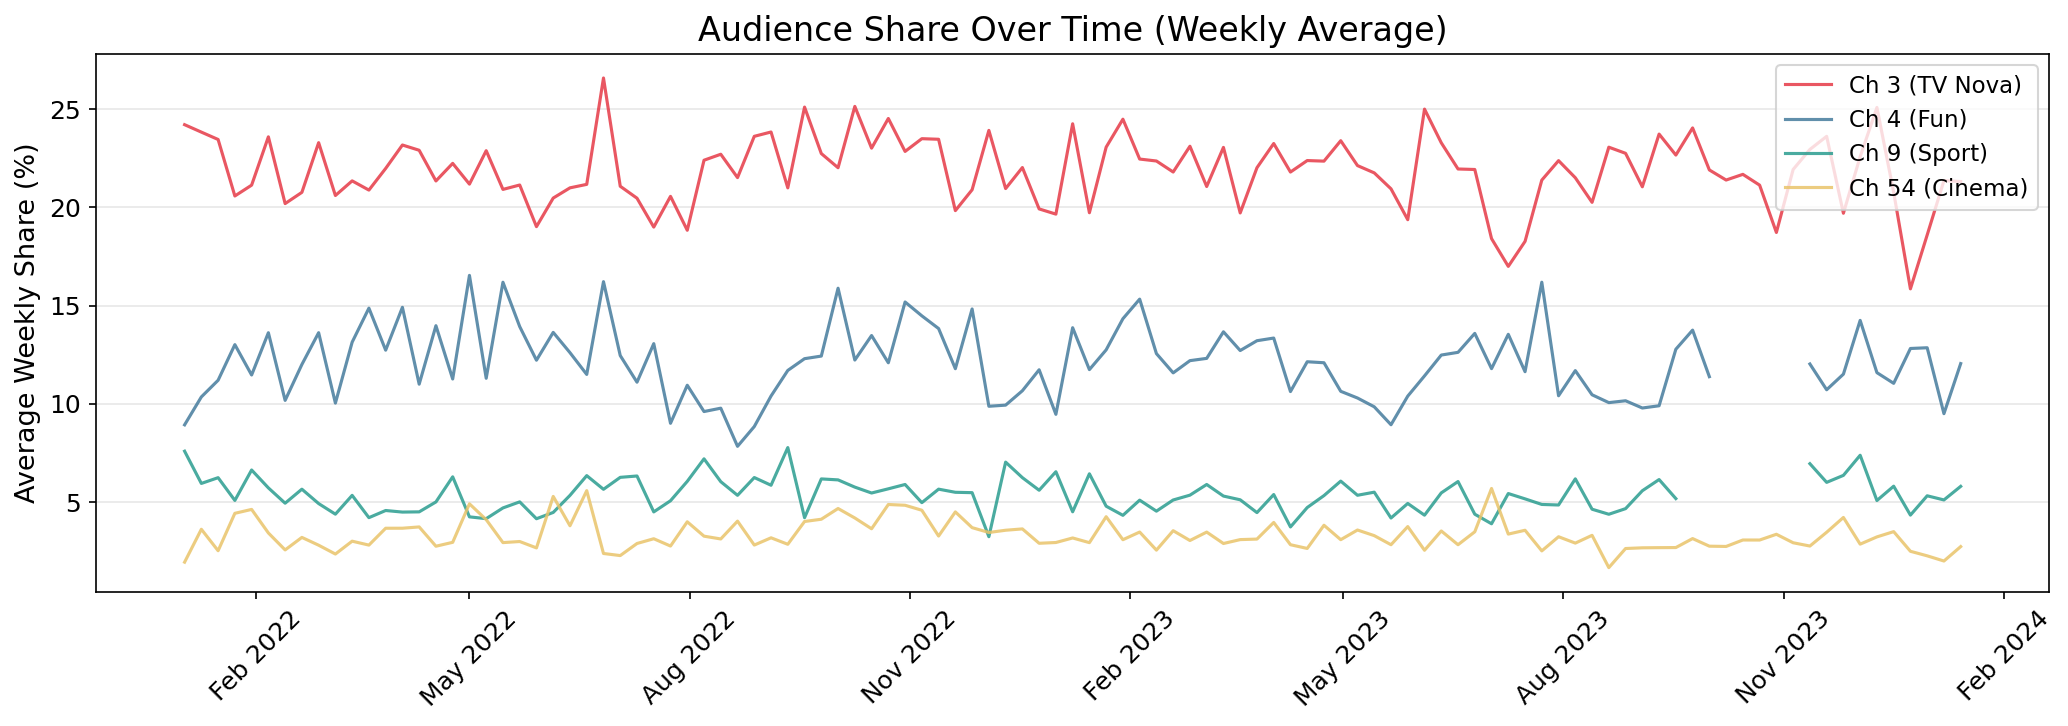

Saved: plots/02_weekly_trend.png


In [38]:
fig, ax = plt.subplots(figsize=(14, 5))
 
for ch in sorted(CHANNEL_COLORS):
    sub = df[df['channel_id'] == ch].set_index('timeslot_datetime_from')['share_15_54']
    weekly = sub.resample('W').mean()
    ax.plot(weekly.index, weekly.values, label=CHANNEL_NAMES[ch],
            color=CHANNEL_COLORS[ch], linewidth=1.5, alpha=0.85)
 
ax.set_ylabel('Average Weekly Share (%)')
ax.set_title('Audience Share Over Time (Weekly Average)')
ax.legend(loc='upper right')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)
 
plt.tight_layout()
plt.savefig("plots/02_weekly_trend.png", bbox_inches='tight')
plt.show()
print("Saved: plots/02_weekly_trend.png")

### Podle hodiny ve dni

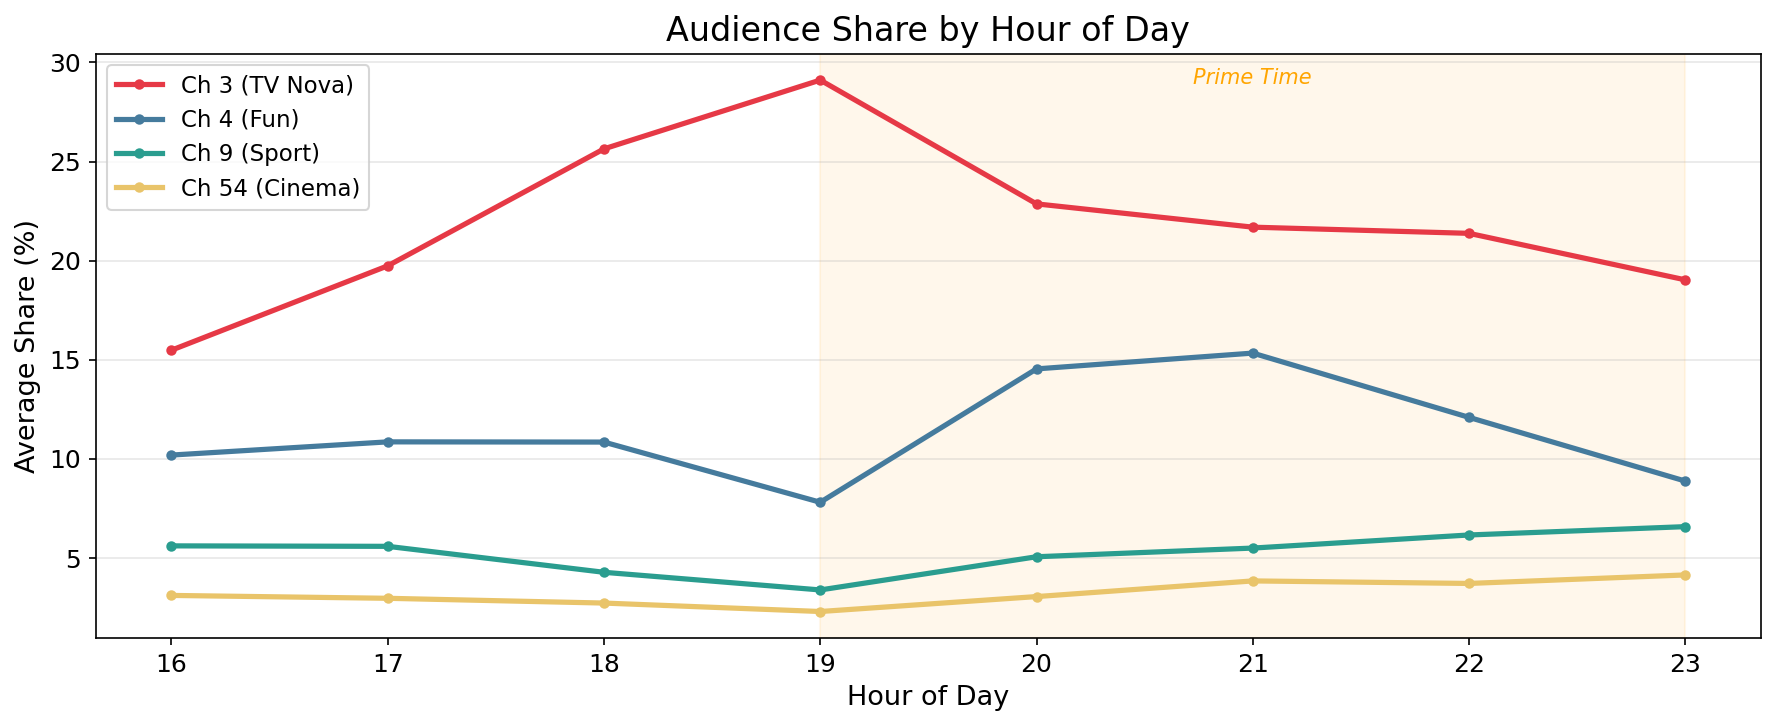

Saved: plots/03_hourly_pattern.png


In [39]:
fig, ax = plt.subplots(figsize=(12, 5))
 
hourly = df.groupby(['hour', 'channel_id'])['share_15_54'].mean().unstack()
for ch in sorted(CHANNEL_COLORS):
    if ch in hourly.columns:
        ax.plot(hourly.index, hourly[ch], label=CHANNEL_NAMES[ch],
                color=CHANNEL_COLORS[ch], linewidth=2.5, marker='o', markersize=4)
 
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Share (%)')
ax.set_title('Audience Share by Hour of Day')
ax.set_xticks(range(0, 24))
ax.legend()
ax.grid(axis='y', alpha=0.3)
 
# Annotate prime time
ax.axvspan(19, 23, alpha=0.08, color='orange', label='Prime time')
ax.text(21, ax.get_ylim()[1] * 0.95, 'Prime Time', ha='center',
        fontsize=10, color='orange', fontstyle='italic')
 
plt.tight_layout()
plt.savefig("plots/03_hourly_pattern.png", bbox_inches='tight')
plt.show()
print("Saved: plots/03_hourly_pattern.png")

### Den v týdnu

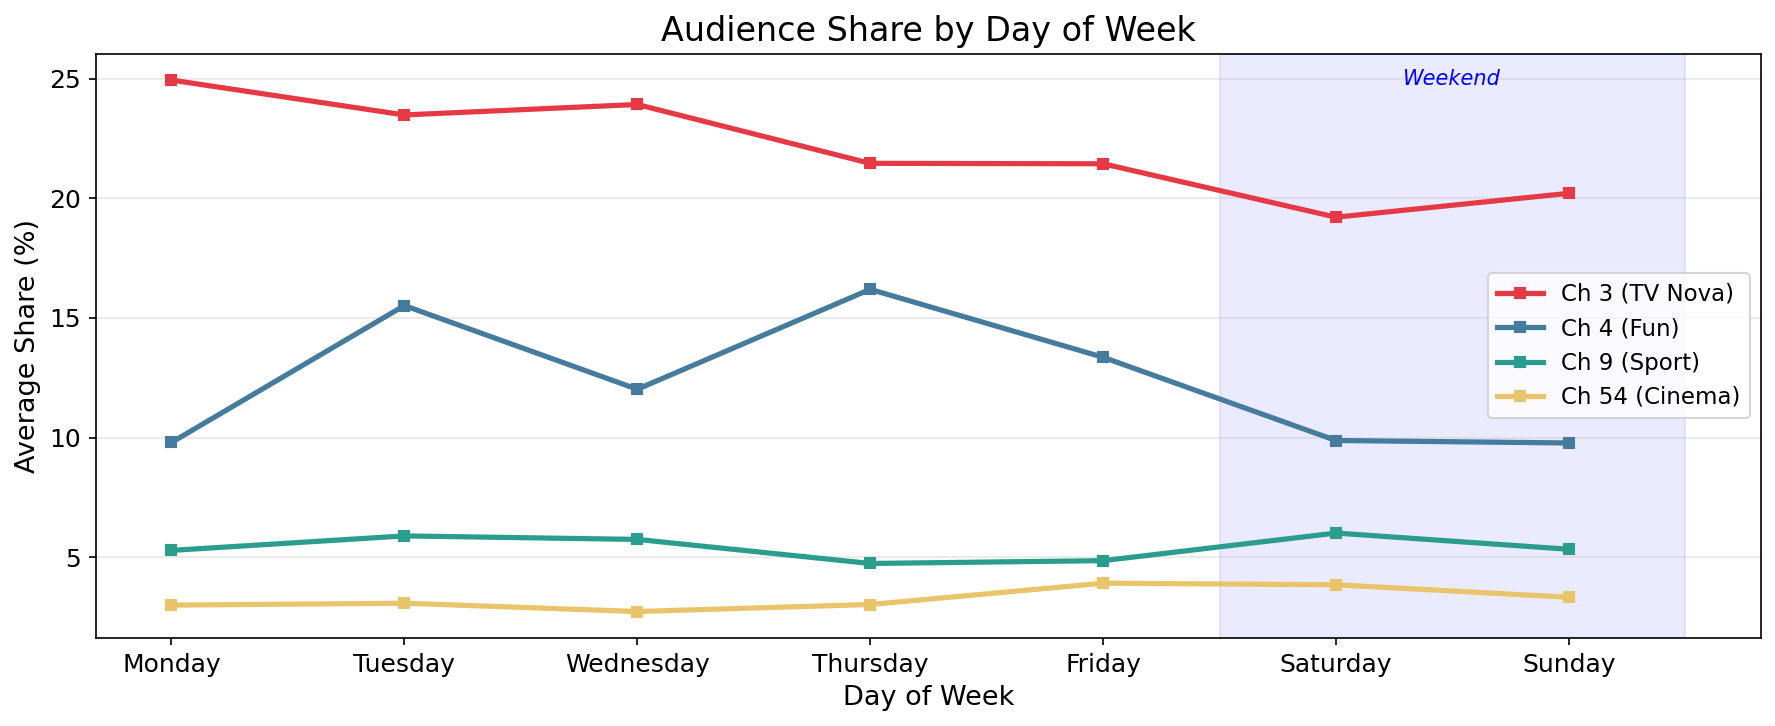

Saved: plots/04_dow_pattern.png


In [41]:
fig, ax = plt.subplots(figsize=(12, 5))
 
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_data = df.groupby(['dow', 'channel_id'])['share_15_54'].mean().unstack()
dow_data = dow_data.loc[dow_order]
 
for ch in sorted(CHANNEL_COLORS):
    if ch in dow_data.columns:
        ax.plot(dow_data.index, dow_data[ch], label=CHANNEL_NAMES[ch],
                color=CHANNEL_COLORS[ch], linewidth=2.5, marker='s', markersize=5)
 
ax.set_xlabel('Day of Week')
ax.set_ylabel('Average Share (%)')
ax.set_title('Audience Share by Day of Week')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.axvspan(4.5, 6.5, alpha=0.08, color='blue')
ax.text(5.5, ax.get_ylim()[1] * 0.95, 'Weekend', ha='center',
        fontsize=10, color='blue', fontstyle='italic')
 
plt.tight_layout()
plt.savefig("plots/04_dow_pattern.png", bbox_inches='tight')
plt.show()
print("Saved: plots/04_dow_pattern.png")

## Cross-channel relationships
Do shares correlate negatively between channels?

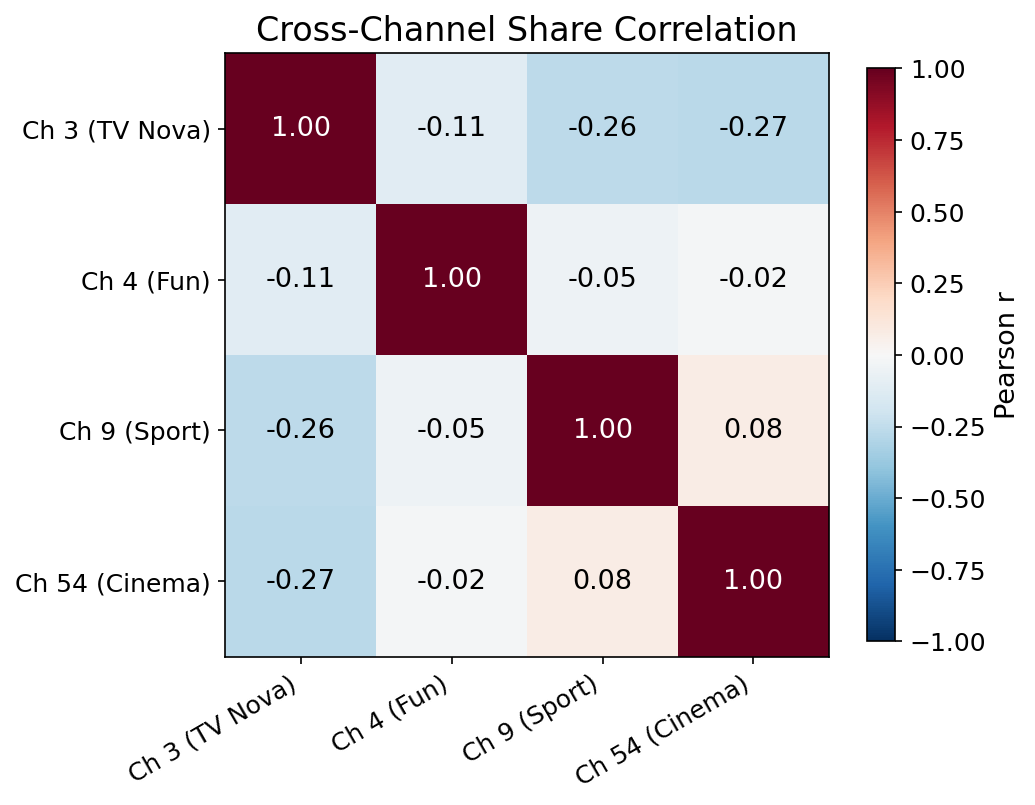

Saved: plots/05_cross_channel_corr.png


In [ ]:
pivot = df.pivot_table(index='timeslot_datetime_from', columns='channel_id', values='share_15_54')
pivot.columns = [CHANNEL_NAMES[c] for c in pivot.columns]
corr = pivot.corr()
 
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
 
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=30, ha='right')
ax.set_yticklabels(corr.index)
 
#popis hodnot v buňkách
for i in range(len(corr)):
    for j in range(len(corr)):
        val = corr.values[i, j]
        color = 'white' if abs(val) > 0.5 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center', color=color, fontsize=13)
 
ax.set_title('Cross-Channel Share Correlation')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
 
plt.tight_layout()
plt.savefig("plots/05_cross_channel_corr.png", bbox_inches='tight')
plt.show()
print("Saved: plots/05_cross_channel_corr.png")

## Genre performance

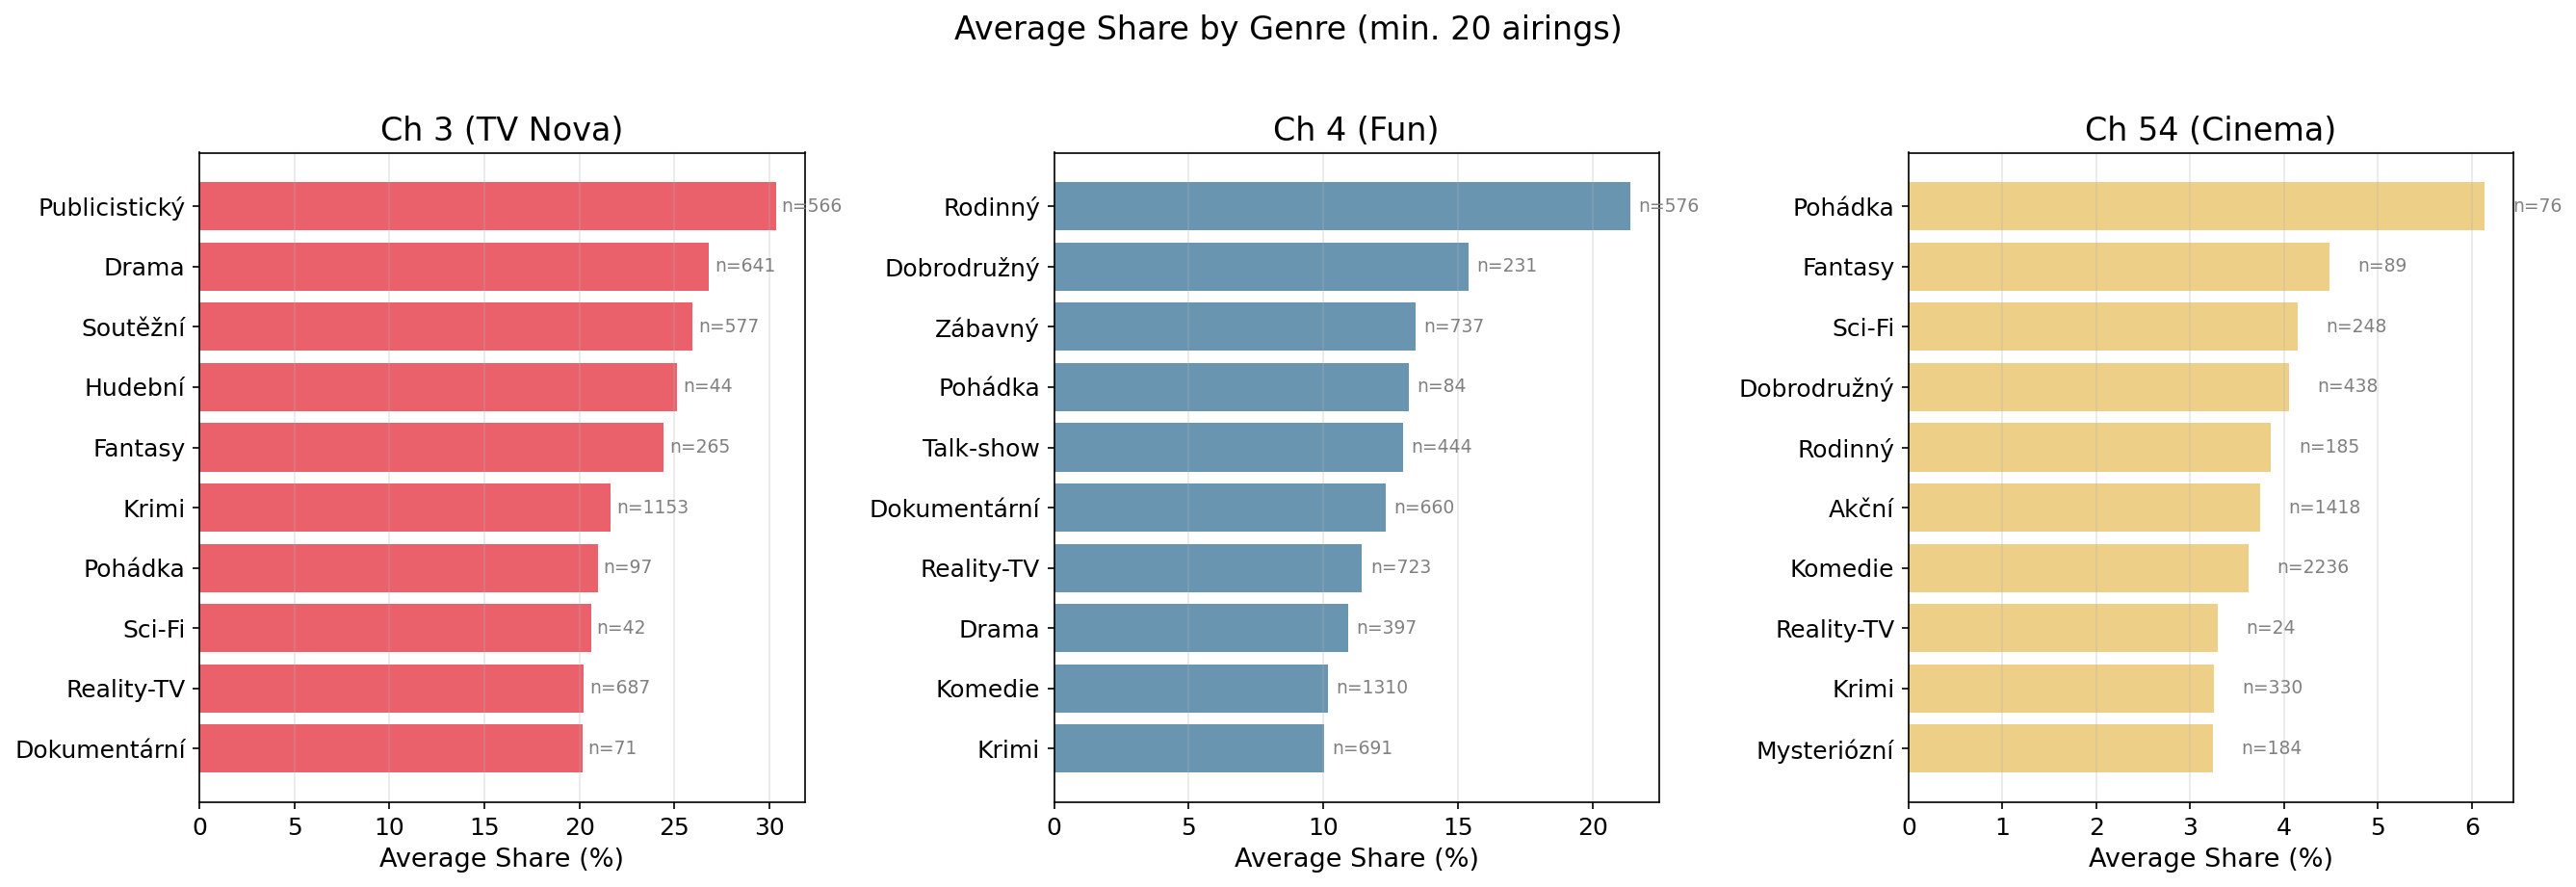

Saved: plots/06_genre_performance.png


In [43]:
genre_cols = {3: 'ch3__f_10', 4: 'ch4__f_10', 54: 'ch54__f_10'}
# Channel 9 has no genre data
 
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
 
for ax, (ch, col) in zip(axes, genre_cols.items()):
    # For each row, we want the genre of the channel that the row belongs to
    # and the share for that row
    mask = (df['channel_id'] == ch) & (df[col].notna())
    genre_share = df.loc[mask].groupby(col)['share_15_54'].agg(['mean', 'count'])
    # Filter genres with at least 20 occurrences for reliability
    genre_share = genre_share[genre_share['count'] >= 20].sort_values('mean', ascending=True)
    # Take top 10
    genre_share = genre_share.tail(10)
 
    bars = ax.barh(genre_share.index, genre_share['mean'], color=CHANNEL_COLORS[ch], alpha=0.8)
    ax.set_xlabel('Average Share (%)')
    ax.set_title(f'{CHANNEL_NAMES[ch]}')
    ax.grid(axis='x', alpha=0.3)
 
    # Add count annotations
    for bar, count in zip(bars, genre_share['count']):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                f'n={int(count)}', va='center', fontsize=9, color='gray')
 
plt.suptitle('Average Share by Genre (min. 20 airings)', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("plots/06_genre_performance.png", bbox_inches='tight')
plt.show()
print("Saved: plots/06_genre_performance.png")

## Kontrola, report

In [46]:
fig, ax = plt.subplots(figsize=(14, 6))
 
# Show null percentage per feature group
null_pct = df.isnull().mean() * 100
# Group by channel prefix
groups = {}
for col in null_pct.index:
    if col.startswith('ch'):
        prefix = col.split('__')[0]
        if prefix not in groups:
            groups[prefix] = {}
        feature_name = col.split('__')[1]
        groups[prefix][feature_name] = null_pct[col]
 
channel_labels = {'ch3': CHANNEL_NAMES[3], 'ch4': CHANNEL_NAMES[4],
                  'ch9': CHANNEL_NAMES[9], 'ch54': CHANNEL_NAMES[54]}
 
features = sorted(set(f for g in groups.values() for f in g))
x = np.arange(len(features))
width = 0.2
 
for i, (prefix, data) in enumerate(sorted(groups.items())):
    vals = [data.get(f, 0) for f in features]
    ax.bar(x + i * width, vals, width, label=channel_labels.get(prefix, prefix),
           color=list(CHANNEL_COLORS.values())[i], alpha=0.8)
 
ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(features, rotation=45, ha='right')
ax.set_ylabel('Missing Values (%)')
ax.set_title('Data Completeness by Feature and Channel')
ax.legend()
ax.grid(axis='y', alpha=0.3)
 
plt.tight_layout()
plt.savefig("plots/07_data_completeness.png", bbox_inches='tight')
plt.show()
print("Saved: plots/07_data_completeness.png")

IndexError: list index out of range

In [ ]:
html_parts = ["""<!DOCTYPE html>
<html><head>
<meta charset="utf-8">
<title>Task 1: Channel Analysis</title>
<style>
  body { font-family: 'Segoe UI', sans-serif; max-width: 1100px; margin: 0 auto;
         padding: 40px 20px; background: #fafafa; color: #222; }
  h1 { border-bottom: 3px solid #e63946; padding-bottom: 10px; }
  h2 { color: #457b9d; margin-top: 40px; }
  img { max-width: 100%; border: 1px solid #ddd; border-radius: 4px;
        margin: 15px 0; box-shadow: 0 2px 8px rgba(0,0,0,0.08); }
  .insight { background: #f0f7ff; border-left: 4px solid #457b9d;
             padding: 12px 18px; margin: 15px 0; border-radius: 0 4px 4px 0; }
  .section { margin-bottom: 50px; }
</style>
</head><body>
<h1>Task 1: Channel Analysis</h1>
<p>Analysis of four channels from the Nova TV group across ~34,000 timeslots
   (Jan 2022 – Jan 2024).</p>
"""]
 
sections = [
    ("Share Dynamics",
     "01_share_dynamics.png",
     "Channel 3 (Flagship) dominates with the highest average share, consistent with a main "
     "generalist channel. Channel 9 (Sport) has the lowest average share but likely spikes "
     "around major sporting events. Channel 54 (Cinema) shows moderate share with high "
     "variance — movie performance is inherently unpredictable."),
 
    ("Weekly Trends",
     "02_weekly_trend.png",
     "The flagship channel shows the strongest seasonal patterns. All channels exhibit "
     "some degree of weekly fluctuation, with potential holiday effects visible as spikes."),
 
    ("Hourly Patterns",
     "03_hourly_pattern.png",
     "Strong prime-time effect (19:00–23:00) across all channels, with the main"
     "channel benefiting the most. Daytime hours show lower, more uniform shares. "
     "This is the single strongest temporal signal for prediction."),
 
    ("Day of Week",
     "04_dow_pattern.png",
     "Weekend viewing patterns differ from weekdays. The sport channel likely shows "
     "the most day-of-week variation due to event scheduling."),
 
    ("Cross-Channel Correlations",
     "05_cross_channel_corr.png",
     "Negative correlations between channels confirm the zero-sum nature of audience share; "
     "when one channel gains viewers, others lose them. This validates the importance of "
     "cross-channel features in prediction models."),
 
    ("Genre Performance",
     "06_genre_performance.png",
     "Genre is a meaningful predictor of share. Reality TV and game shows drive high share "
     "on Channel 3 (main), while drama and action perform well on the cinema channel. "
     "Channel 9 (Sport) has no genre metadata: sport broadcasts don't carry this information."),
 
    ("Data Completeness",
     "07_data_completeness.png",
     "Channel 9 is systematically missing features f_7 through f_11 (100% null), consistent "
     "with a sport channel lacking movie-style metadata. Other channels have varying "
     "levels of missingness that need handling in the modeling phase."),
]
 

In [49]:

import base64
 
for title, img_file, insight in sections:
    img_path = f"plots/{img_file}"
    if os.path.exists(img_path):
        with open(img_path, "rb") as f:
            img_b64 = base64.b64encode(f.read()).decode()
        html_parts.append(f"""
<div class="section">
  <h2>{title}</h2>
  <img src="data:image/png;base64,{img_b64}" alt="{title}">
  <div class="insight"><strong>Result:</strong> {insight}</div>
</div>""")
 
html_parts.append("</body></html>")
 
with open("task1_report.html", "w", encoding="utf-8") as f:
    f.write("\n".join(html_parts))